     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 26.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 8.4 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
DEEP LEARNING OBJECT DETECTION USING YOLOv8

[1] Loading YOLOv8 model...
✓ YOLOv8 model loaded successfully

[2] Downloading sample image...
✓ Sample image downloaded


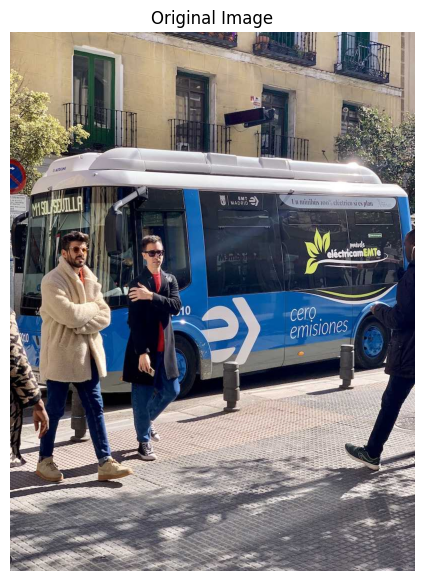


[3] Performing object detection...

image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 361.8ms
Speed: 27.0ms preprocess, 361.8ms inference, 37.6ms postprocess per image at shape (1, 3, 640, 480)
✓ Detection completed


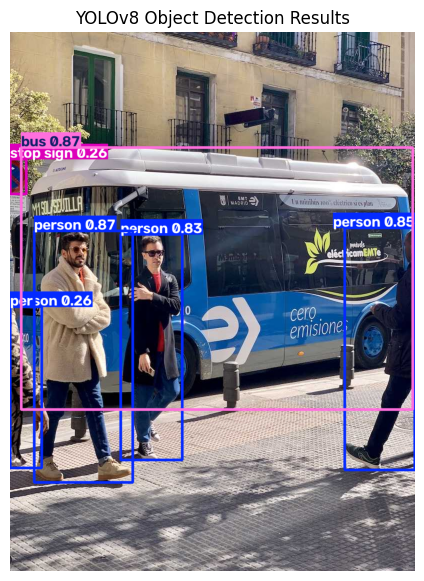


[4] DETECTED OBJECTS
------------------------------------------------------------
Object: bus             Confidence: 0.87
Object: person          Confidence: 0.87
Object: person          Confidence: 0.85
Object: person          Confidence: 0.83
Object: person          Confidence: 0.26
Object: stop sign       Confidence: 0.26

[5] DETECTION RESULTS TABLE
------------------------------------------------------------


,Object,Confidence,X1,Y1,X2,Y2
0,bus,0.873,22.9,231.3,805.0,756.8
1,person,0.866,48.6,398.6,245.3,902.7
2,person,0.853,669.5,392.2,809.7,877.0
3,person,0.825,221.5,405.8,345.0,857.5
4,person,0.261,0.0,550.5,63.0,873.4
5,stop sign,0.255,0.1,254.5,32.6,324.9



[6] OBJECT COUNT
------------------------------------------------------------
Object
person       4
bus          1
stop sign    1
Name: count, dtype: int64


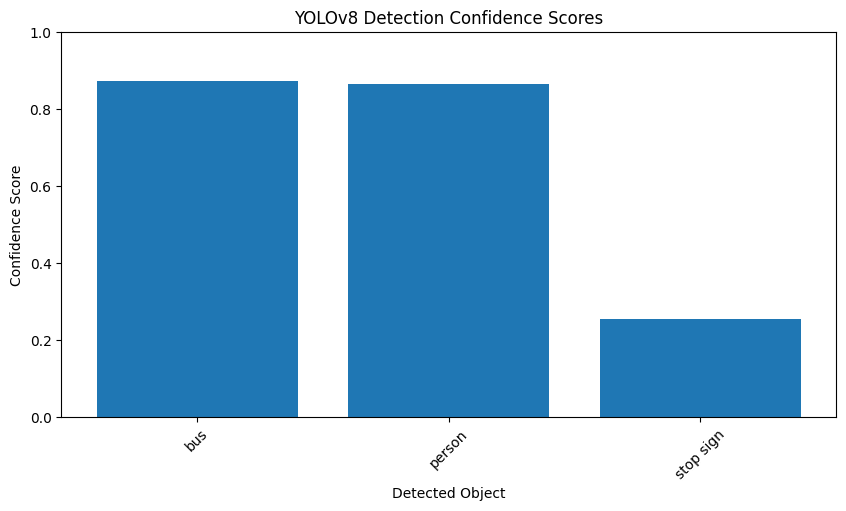


[7] PERFORMANCE
------------------------------------------------------------
Inference Time : 6.7205 seconds
Approx. FPS    : 0.15

EXPERIMENT SUMMARY
Total objects detected : 6
Unique object classes  : 3
Inference time         : 6.7205 seconds
Approximate FPS        : 0.15

✓ Object detection experiment completed successfully!


In [ ]:
# ============================================================
# Deep Learning-Based Object Detection using YOLOv8
# ============================================================

# Install required libraries
!pip install -q ultralytics opencv-python matplotlib pandas

# Import libraries
import cv2
import time
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

print("=" * 60)
print("DEEP LEARNING OBJECT DETECTION USING YOLOv8")
print("=" * 60)

# ------------------------------------------------------------
# 1. Load Pre-trained YOLOv8 Model
# ------------------------------------------------------------
print("\n[1] Loading YOLOv8 model...")

model = YOLO("yolov8n.pt")

print("✓ YOLOv8 model loaded successfully")

# ------------------------------------------------------------
# 2. Download Sample Image
# ------------------------------------------------------------
print("\n[2] Downloading sample image...")

!wget -q https://ultralytics.com/images/bus.jpg -O bus.jpg

print("✓ Sample image downloaded")

# ------------------------------------------------------------
# 3. Display Original Image
# ------------------------------------------------------------
image = cv2.imread("bus.jpg")
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 7))
plt.imshow(image_rgb)
plt.axis("off")
plt.title("Original Image")
plt.show()

# ------------------------------------------------------------
# 4. Perform Object Detection
# ------------------------------------------------------------
print("\n[3] Performing object detection...")

start_time = time.time()

results = model("bus.jpg")

end_time = time.time()

inference_time = end_time - start_time
fps = 1 / inference_time

print("✓ Detection completed")

# ------------------------------------------------------------
# 5. Display Detection Results
# ------------------------------------------------------------
result = results[0]

annotated_image = result.plot()
annotated_rgb = cv2.cvtColor(
    annotated_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 7))
plt.imshow(annotated_rgb)
plt.axis("off")
plt.title("YOLOv8 Object Detection Results")
plt.show()

# ------------------------------------------------------------
# 6. Extract Detection Information
# ------------------------------------------------------------
detections = []

print("\n[4] DETECTED OBJECTS")
print("-" * 60)

for box in result.boxes:

    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    class_name = model.names[class_id]

    x1, y1, x2, y2 = box.xyxy[0].tolist()

    detections.append({
        "Object": class_name,
        "Confidence": round(confidence, 3),
        "X1": round(x1, 1),
        "Y1": round(y1, 1),
        "X2": round(x2, 1),
        "Y2": round(y2, 1)
    })

    print(
        f"Object: {class_name:<15} "
        f"Confidence: {confidence:.2f}"
    )

# ------------------------------------------------------------
# 7. Create Results DataFrame
# ------------------------------------------------------------
df = pd.DataFrame(detections)

print("\n[5] DETECTION RESULTS TABLE")
print("-" * 60)

display(df)

# ------------------------------------------------------------
# 8. Count Detected Objects
# ------------------------------------------------------------
print("\n[6] OBJECT COUNT")
print("-" * 60)

object_counts = df["Object"].value_counts()

print(object_counts)

# ------------------------------------------------------------
# 9. Confidence Score Visualization
# ------------------------------------------------------------
plt.figure(figsize=(10, 5))

plt.bar(
    df["Object"],
    df["Confidence"]
)

plt.xlabel("Detected Object")
plt.ylabel("Confidence Score")
plt.title("YOLOv8 Detection Confidence Scores")
plt.ylim(0, 1)
plt.xticks(rotation=45)

plt.show()

# ------------------------------------------------------------
# 10. Performance
# ------------------------------------------------------------
print("\n[7] PERFORMANCE")
print("-" * 60)

print(f"Inference Time : {inference_time:.4f} seconds")
print(f"Approx. FPS    : {fps:.2f}")

# ------------------------------------------------------------
# 11. Summary
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("EXPERIMENT SUMMARY")
print("=" * 60)

print(f"Total objects detected : {len(df)}")
print(f"Unique object classes  : {df['Object'].nunique()}")
print(f"Inference time         : {inference_time:.4f} seconds")
print(f"Approximate FPS        : {fps:.2f}")

print("\n✓ Object detection experiment completed successfully!")

# ============================================================
# QUESTION & ANSWERS
# Deep Learning-Based Object Detection and Recognition
# ============================================================

from IPython.display import display, Markdown

qa = r"""
# Deep Learning-Based Object Detection and Recognition
## Question & Answers

---

### 1. Differentiate between image classification, object detection, and image segmentation.

| Technique | Description | Output |
|---|---|---|
| **Image Classification** | Identifies the category or class of the image. | Class label |
| **Object Detection** | Identifies multiple objects and their locations. | Class label + Bounding box |
| **Image Segmentation** | Classifies individual pixels belonging to different objects. | Pixel-level mask |

**Example:** In an image containing a car and a person, classification identifies the objects, detection draws bounding boxes around them, while segmentation identifies the exact pixels belonging to each object.

---

### 2. Explain the working principle of the YOLO object detection algorithm.

**YOLO (You Only Look Once)** is a one-stage object detection algorithm.

Its working process is:

1. The input image is given to the YOLO neural network.
2. The network processes the complete image in a single forward pass.
3. It predicts bounding boxes, class probabilities, and confidence scores.
4. Low-confidence predictions can be removed using a confidence threshold.
5. Non-Maximum Suppression (NMS) removes duplicate overlapping bounding boxes.
6. The final output contains the detected objects, their locations, and confidence scores.

The major advantage of YOLO is its high detection speed, making it suitable for real-time applications.

---

### 3. Compare YOLO, SSD, and Faster R-CNN based on speed, accuracy, and applications.

| Feature | YOLO | SSD | Faster R-CNN |
|---|---|---|---|
| Architecture | One-stage | One-stage | Two-stage |
| Speed | Very fast | Fast | Relatively slower |
| Accuracy | High | High | Generally very high |
| Real-time Detection | Excellent | Good | Less suitable than YOLO/SSD |
| Small Object Detection | Can be challenging | Can be challenging | Generally better |
| Complexity | Relatively low | Moderate | High |
| Applications | Surveillance, robotics, autonomous systems | Mobile and embedded vision | High-accuracy detection and research |

YOLO and SSD focus strongly on speed, while Faster R-CNN uses a two-stage approach and generally provides strong localization accuracy at a higher computational cost.

---

### 4. What is a bounding box? Why is it important in object detection?

A **bounding box** is a rectangular box drawn around a detected object.

It is normally represented using coordinates such as:

- `(x1, y1)` → Top-left corner
- `(x2, y2)` → Bottom-right corner

Bounding boxes are important because they provide the **location of an object** within an image.

For example, if YOLO detects a car, the bounding box tells us exactly where the car is located.

---

### 5. Explain the significance of confidence score and Intersection over Union (IoU).

#### Confidence Score

A confidence score indicates how confident the model is that a particular detection belongs to a specific object class.

Example:

```text
Person → 0.92
Car    → 0.87
Dog    → 0.65




6. What are the advantages of using pre-trained deep learning models over traditional image processing techniques?

Pre-trained deep learning models have several advantages:

1. They have already learned useful visual features from large datasets.
2. They reduce training time and computational requirements.
3. They automatically learn complex patterns from images.
4. They generally perform well on complex real-world images.
5. They can be fine-tuned for specific applications.
6. They reduce the need for manually designed features.
7. They can handle variations in object size, position, shape, and appearance.

Traditional image processing techniques often depend on manually designed features such as edges, colors, and shapes, whereas deep learning models learn useful features automatically.

⸻

7. Why are datasets such as MS COCO and Pascal VOC widely used for object detection research?

MS COCO and Pascal VOC are widely used because they provide standardized datasets for training and evaluating object detection models.

They contain:

* Large collections of images
* Multiple object categories
* Bounding-box annotations
* Labeled objects
* Standard evaluation methods

These datasets allow researchers to train and compare different object detection algorithms using common benchmarks.

They also contain diverse images with objects appearing in different sizes, positions, and environments.

⸻

8. Mention five real-world applications of object detection in computer vision.

Five important applications are:

1. Autonomous Vehicles

Detecting vehicles, pedestrians, traffic signs, and other road objects.

2. Surveillance Systems

Detecting people, vehicles, and other objects for monitoring.

3. Healthcare

Detecting objects or abnormalities in medical images.

4. Retail Analytics

Detecting products and analyzing customer activity.

5. Industrial Inspection

Detecting defective or damaged products on production lines.

Other applications include:

* Agriculture
* Robotics
* Sports analytics
* Smart cities
* Traffic monitoring

⸻

9. What challenges are commonly encountered while detecting objects in complex real-world environments?

Common challenges include:

1. Occlusion – Objects may be partially hidden by other objects.
2. Poor Lighting – Darkness or excessive brightness can affect detection.
3. Small Objects – Small objects can be difficult to detect accurately.
4. Object Overlap – Multiple objects may overlap with each other.
5. Background Clutter – Complex backgrounds can cause false detections.
6. Different Object Scales – Objects may appear at different sizes.
7. Motion Blur – Moving objects may become unclear.
8. Different Viewpoints – Objects can look different from different angles.
9. Weather Conditions – Rain, fog, snow, or dust can reduce detection quality.
10. Computational Limitations – Advanced models may require powerful hardware.

⸻

10. How can object detection systems be further improved using recent advancements in deep learning and computer vision?

Object detection systems can be improved using several modern techniques:

1. Transfer Learning – Using powerful pre-trained models.
2. Data Augmentation – Creating diverse training examples.
3. Better Neural Network Architectures – Improving accuracy and efficiency.
4. Transformer-based Models – Improving feature representation and detection.
5. Attention Mechanisms – Helping models focus on important image regions.
6. Larger and More Diverse Datasets – Improving model generalization.
7. Model Quantization – Reducing model size and computational requirements.
8. GPU/AI Hardware Acceleration – Improving inference speed.
9. Multi-scale Feature Detection – Improving detection of small objects.
10. Edge AI – Enabling real-time detection on cameras and embedded devices.